# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** I Nyoman Restu Dharmayasa
- **Email:** restudharmayasa@gmail.com
- **ID Dicoding:** DS014B6Y0762

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbandingan rata-rata jumlah penyewaan sepeda harian berdasarkan kondisi cuaca dan musim sepanjang tahun 2011 hingga 2012?
- **Pertanyaan 2:** Bagaimana perbedaan pola rata-rata penyewaan sepeda harian antara pengguna casual dan registered pada hari kerja dibandingkan hari libur/akhir pekan selama periode 2011–2012?
- **Pertanyaan 3:** Pada kelompok kategori waktu manakah terjadi puncak rata-rata penyewaan sepeda per jam, serta bagaimana perbandingan proporsi pengguna casual dan registered di setiap kategori waktu tersebut selama tahun 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Data Wrangling

### Gathering Data

#### Load df day.csv dan hour.csv

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- day.csv berhasil dimuat ke dalam day_df dengan 16 kolom yang berisi data penyewaan sepeda harian.
- hour.csv berhasil dimuat ke dalam hour_df dengan 17 kolom yang memuat detail penyewaan per jam melalui kolom tambahan.

### Assessing Data

#### Identifying day_df and hour_df problem

In [4]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [5]:
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [6]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [9]:
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [10]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [11]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Steps to Take:**
- Mengubah tipe data kolom dteday menjadi datetime pada kedua DataFrame.
- Mengonversi kode angka pada kolom kategorikal (season, yr, mnth, weathersit, weekday, workingday, holiday) menjadi keterangan teks agar mudah dianalisis dan divisualisasikan.
- Menghapus kolom instant karena hanya berfungsi sebagai nomor indeks baris.

**Insight:** (Opsional)
- Tidak ada missing value maupun duplikasi pada day_df maupun hour_df.
- Ditemukan 2 permasalahan data yaitu tipe data kolom dteday masih object yang seharusnya datetime, dan variabel kategorikal seperti season, yr, mnth, weathersit, dan weekday masih berupa kode angka sehingga kurang informatif.

### Cleaning Data

Fixing day_df dan hour_df problem

In [12]:
day_df.drop(columns=['instant'], inplace=True)
hour_df.drop(columns=['instant'], inplace=True)

In [13]:
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [14]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
mnth_map = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
            7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
weathersit_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Ice Pellets'
}
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
               4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
workingday_map = {0: 'Weekend/Holiday', 1: 'Working Day'}

for df in [day_df, hour_df]:
    df['season'] = df['season'].map(season_map)
    df['yr'] = df['yr'].map(yr_map)
    df['mnth'] = df['mnth'].map(mnth_map)
    df['weathersit'] = df['weathersit'].map(weathersit_map)
    df['weekday'] = df['weekday'].map(weekday_map)
    df['workingday'] = df['workingday'].map(workingday_map)

In [15]:
day_df.info()
day_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      731 non-null    datetime64[ns]
 1   season      731 non-null    object        
 2   yr          731 non-null    int64         
 3   mnth        731 non-null    object        
 4   holiday     731 non-null    int64         
 5   weekday     731 non-null    object        
 6   workingday  731 non-null    object        
 7   weathersit  731 non-null    object        
 8   temp        731 non-null    float64       
 9   atemp       731 non-null    float64       
 10  hum         731 non-null    float64       
 11  windspeed   731 non-null    float64       
 12  casual      731 non-null    int64         
 13  registered  731 non-null    int64         
 14  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), float64(4), int64(5), object(5)
memory usage: 85.8+ 

,dteday,yr,holiday,temp,atemp,hum,windspeed,casual,registered,cnt
count,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,2012-01-01 00:00:00,2011.500684,0.028728,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,2011-01-01 00:00:00,2011.000000,0.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,2011-07-02 12:00:00,2011.000000,0.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,2012-01-01 00:00:00,2012.000000,0.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,2012-07-01 12:00:00,2012.000000,0.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,2012-12-31 00:00:00,2012.000000,1.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,NaN,0.500342,0.167155,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [16]:
day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,Jan,0,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-02,Spring,2011,Jan,0,Sunday,Weekend/Holiday,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,2011-01-03,Spring,2011,Jan,0,Monday,Working Day,Clear/Partly Cloudy,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,2011-01-04,Spring,2011,Jan,0,Tuesday,Working Day,Clear/Partly Cloudy,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,2011-01-05,Spring,2011,Jan,0,Wednesday,Working Day,Clear/Partly Cloudy,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [17]:
hour_df.info()
hour_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[ns]
 1   season      17379 non-null  object        
 2   yr          17379 non-null  int64         
 3   mnth        17379 non-null  object        
 4   hr          17379 non-null  int64         
 5   holiday     17379 non-null  int64         
 6   weekday     17379 non-null  object        
 7   workingday  17379 non-null  object        
 8   weathersit  17379 non-null  object        
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  casual      17379 non-null  int64         
 14  registered  17379 non-null  int64         
 15  cnt         17379 non-null  int64         
dtypes: datetime64[ns](1), 

,dteday,yr,hr,holiday,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,2012-01-02 04:08:34.552045568,2011.502561,11.546752,0.028770,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,2011-01-01 00:00:00,2011.000000,0.000000,0.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-04 00:00:00,2011.000000,6.000000,0.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,2012-01-02 00:00:00,2012.000000,12.000000,0.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,2012-07-02 00:00:00,2012.000000,18.000000,0.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,2012-12-31 00:00:00,2012.000000,23.000000,1.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,NaN,0.500008,6.914405,0.167165,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


In [18]:
hour_df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,2011-01-01,Spring,2011,Jan,0,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,0.2879,0.81,0.0,3,13,16
1,2011-01-01,Spring,2011,Jan,1,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,8,32,40
2,2011-01-01,Spring,2011,Jan,2,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.22,0.2727,0.80,0.0,5,27,32
3,2011-01-01,Spring,2011,Jan,3,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,3,10,13
4,2011-01-01,Spring,2011,Jan,4,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Kolom instant berhasil dihapus dari kedua tabel sehingga sisa kolom bersih menjadi 15 pada day_df dan 16 pada hour_df.
- Tipe data kolom dteday pada kedua tabel sudah berhasil diubah menjadi datetime64[ns].
- Seluruh kode angka pada kolom kategorikal telah terkonversi menjadi label deskriptif tanpa menimbulkan nilai kosong.

## Exploratory Data Analysis (EDA)

### Explore Pengaruh Musim, Cuaca, Jenis Hari, dan Waktu terhadap Penyewaan Sepeda

In [19]:
day_df.describe(include="all")

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731,731,731.000000,731,731.000000,731,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,4,NaN,12,NaN,7,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,Fall,NaN,Jan,NaN,Saturday,Working Day,Clear/Partly Cloudy,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,188,NaN,62,NaN,105,500,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2012-01-01 00:00:00,NaN,2011.500684,NaN,0.028728,NaN,NaN,NaN,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,2011-01-01 00:00:00,NaN,2011.000000,NaN,0.000000,NaN,NaN,NaN,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,2011-07-02 12:00:00,NaN,2011.000000,NaN,0.000000,NaN,NaN,NaN,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,2012-01-01 00:00:00,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,2012-07-01 12:00:00,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,2012-12-31 00:00:00,NaN,2012.000000,NaN,1.000000,NaN,NaN,NaN,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [20]:
day_df.groupby(by="season").agg({
    "cnt": ["max", "min", "mean", "sum"],
    "casual": "mean",
    "registered": "mean"
}).sort_values(by=("cnt", "mean"), ascending=False)

cnt                                   casual   registered
         max   min         mean      sum         mean         mean
season                                                            
Fall    8714  1115  5644.303191  1061129  1202.611702  4441.691489
Summer  8362   795  4992.331522   918589  1106.097826  3886.233696
Winter  8555    22  4728.162921   841613   729.112360  3999.050562
Spring  7836   431  2604.132597   471348   334.928177  2269.204420

In [21]:
day_df.groupby(by="weathersit").agg({
    "cnt": ["max", "min", "mean", "sum"],
    "casual": "mean",
    "registered": "mean"
}).sort_values(by=("cnt", "mean"), ascending=False)

cnt                                 casual   registered
                      max  min         mean      sum        mean         mean
weathersit                                                                   
Clear/Partly Cloudy  8714  431  4876.786177  2257952  964.030238  3912.755940
Mist/Cloudy          8362  605  4035.862348   996858  687.352227  3348.510121
Light Snow/Rain      4639   22  1803.285714    37869  185.476190  1617.809524

In [22]:
day_df.groupby(by="workingday").agg({
    "casual": ["mean", "sum"],
    "registered": ["mean", "sum"],
    "cnt": ["mean", "sum"]
})

casual           registered                   cnt  \
                        mean     sum         mean      sum         mean   
workingday                                                                
Weekend/Holiday  1371.134199  316732  2959.034632   683537  4330.168831   
Working Day       606.570000  303285  3978.250000  1989125  4584.820000   

                          
                     sum  
workingday                
Weekend/Holiday  1000269  
Working Day      2292410

In [23]:
hour_df["time_category"] = hour_df.hr.apply(
    lambda x: "Pagi (00-10)" if x <= 10 else (
        "Siang (11-14)" if x <= 14 else (
            "Sore (15-18)" if x <= 18 else "Malam (19-23)"
        )
    )
)

hour_df.groupby(by="time_category").agg({
    "cnt": ["max", "min", "mean", "sum"],
    "casual": "mean",
    "registered": "mean"
}).sort_values(by=("cnt", "mean"), ascending=False)

cnt                              casual  registered
               max min        mean      sum       mean        mean
time_category                                                     
Sore (15-18)   977   7  362.539938  1057529  71.016798  291.523140
Siang (11-14)  776   3  239.033642   696305  68.934432  170.099210
Malam (19-23)  743   2  185.806868   676337  30.142308  155.664560
Pagi (00-10)   839   1  109.053989   862508  12.939310   96.114679

**Insight:** (Opsional)
- Rata-rata penyewaan tertinggi terjadi pada musim gugur sebesar 5.644 sepeda/hari dan terendah pada musim semi sebesar 2.604 sepeda/hari. Dari sisi cuaca, kondisi cerah mencatat rata-rata tertinggi, jauh di atas kondisi hujan/salju ringan.
- Pengguna registered jauh lebih aktif pada hari kerja dibandingkan akhir pekan. Sebaliknya, pengguna casual melonjak lebih dari dua kali lipat saat akhir pekan/libur dibandingkan hari kerja.
- Puncak rata-rata penyewaan per jam terjadi pada kategori Sore (15–18) sebesar 363 sepeda/jam, diikuti Siang (11–14) dan Malam (19–23), sedangkan aktivitas terendah terjadi pada Pagi (00–10) sebesar 109 sepeda/jam. Di seluruh kategori waktu, pengguna registered mendominasi proporsi penyewaan sekitar 71% hingga 88%, sementara proporsi tertinggi pengguna casual muncul pada kategori Siang (11–14) sekitar 29%.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_37095/3941061403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_37095/3941061403.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_37095/3941061403.py:27: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.barplot(


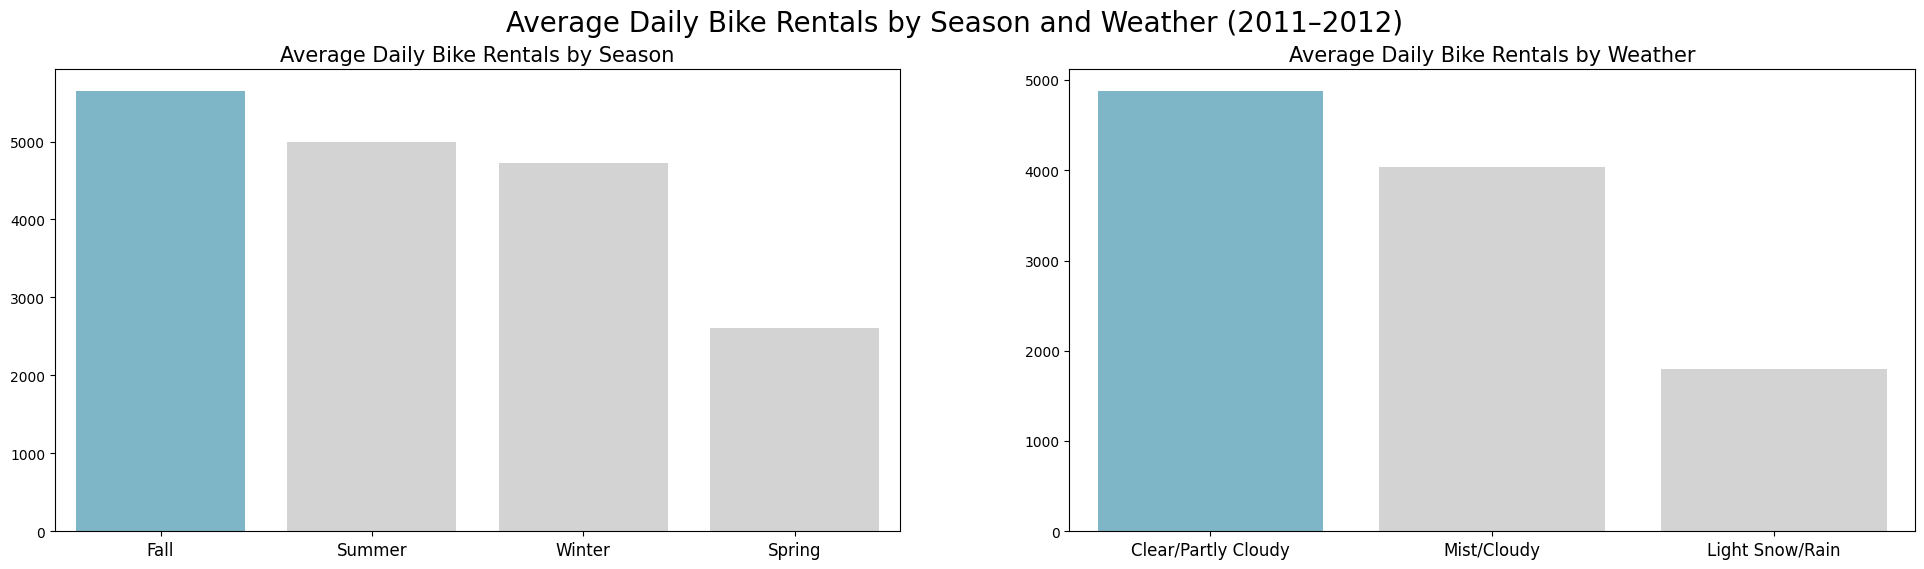

In [24]:
byseason_df = day_df.groupby(by="season").cnt.mean().reset_index()
byseason_df.rename(columns={
    "cnt": "avg_rental"
}, inplace=True)

byweather_df = day_df.groupby(by="weathersit").cnt.mean().reset_index()
byweather_df.rename(columns={
    "cnt": "avg_rental"
}, inplace=True)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

colors = ["#72BCD4", "#D3D3D3", "#D3D3D3", "#D3D3D3"]

sns.barplot(
    y="avg_rental",
    x="season",
    data=byseason_df.sort_values(by="avg_rental", ascending=False),
    palette=colors,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("Average Daily Bike Rentals by Season", loc="center", fontsize=15)
ax[0].tick_params(axis='x', labelsize=12)

sns.barplot(
    y="avg_rental",
    x="weathersit",
    data=byweather_df.sort_values(by="avg_rental", ascending=False),
    palette=colors,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("Average Daily Bike Rentals by Weather", loc="center", fontsize=15)
ax[1].tick_params(axis='x', labelsize=12)

plt.suptitle("Average Daily Bike Rentals by Season and Weather (2011–2012)", fontsize=20)
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_37095/361226206.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_37095/361226206.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


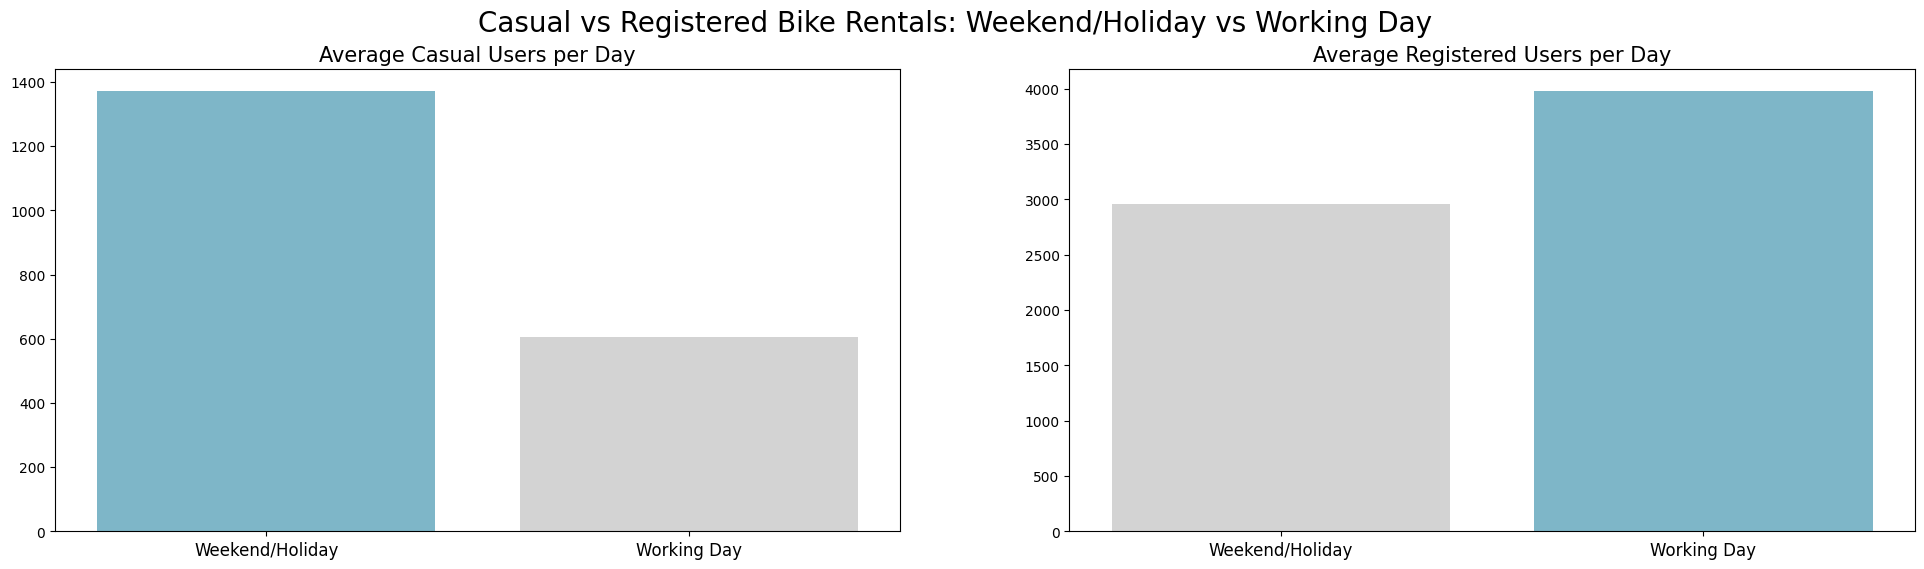

In [25]:
byworkingday_df = day_df.groupby(by="workingday")[["casual", "registered"]].mean().reset_index()

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

colors_casual = ["#72BCD4", "#D3D3D3"]
colors_registered = ["#D3D3D3", "#72BCD4"]

sns.barplot(
    y="casual",
    x="workingday",
    data=byworkingday_df,
    palette=colors_casual,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("Average Casual Users per Day", loc="center", fontsize=15)
ax[0].tick_params(axis='x', labelsize=12)

sns.barplot(
    y="registered",
    x="workingday",
    data=byworkingday_df,
    palette=colors_registered,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("Average Registered Users per Day", loc="center", fontsize=15)
ax[1].tick_params(axis='x', labelsize=12)

plt.suptitle("Casual vs Registered Bike Rentals: Weekend/Holiday vs Working Day", fontsize=20)
plt.show()

**Insight:** (Opsional)
- Grafik menunjukkan bahwa musim gugur mencatat rata-rata penyewaan harian tertinggi sebesar 5.644 sepeda/hari, sedangkan musim semi terendah sebesar 2.604 sepeda/hari.
- Pada faktor cuaca, kondisi cerah/berawan sebagian mendominasi dengan rata-rata 4.877 sepeda/hari, sementara cuaca hujan/salju ringan turun drastis hingga 1.803 sepeda/hari dan tidak tercatat aktivitas penyewaan pada cuaca ekstrem.
- Terdapat kontras perilaku yang jelas antara dua segmen pengguna. Pengguna registered jauh lebih tinggi pada hari kerja dengan rata-rata 3.978 sepeda/hari dibandingkan akhir pekan yaitu 2.959 sepeda/hari, sedangkan pengguna casual justru melonjak lebih dari dua kali lipat pada akhir pekan/libur sebesar 1.371 sepeda/hari dibandingkan hari kerja yaitu 607 sepeda/hari.

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_37095/1627646381.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_37095/1627646381.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_37095/1627646381.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


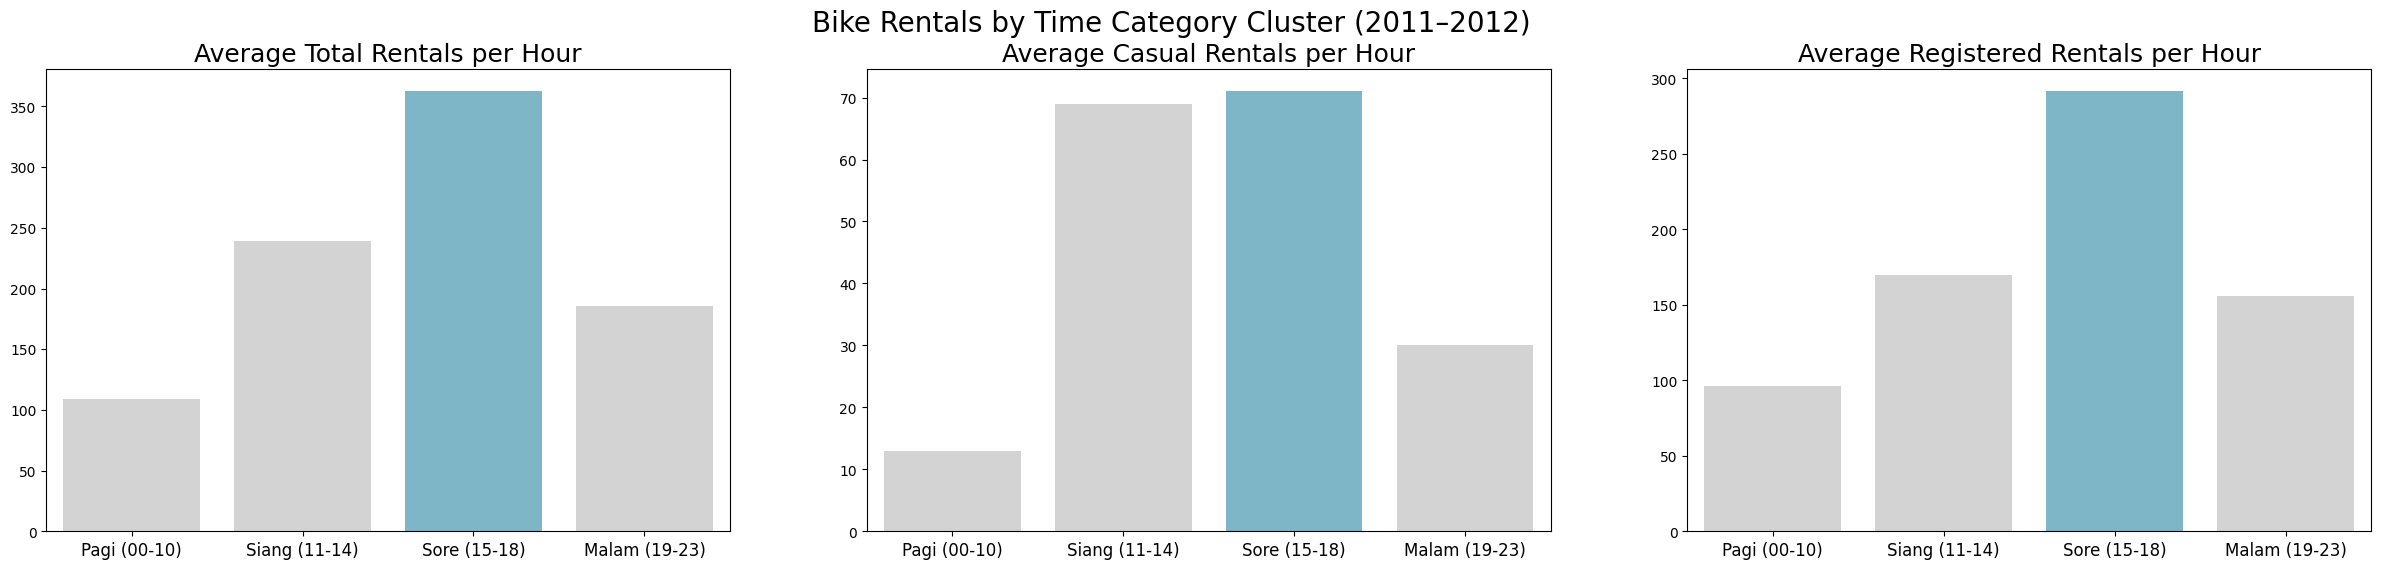

In [26]:
bytime_df = hour_df.groupby(by="time_category").agg({
    "cnt": "mean",
    "casual": "mean",
    "registered": "mean"
}).reset_index()

bytime_df['time_category'] = pd.Categorical(
    bytime_df['time_category'],
    ["Pagi (00-10)", "Siang (11-14)", "Sore (15-18)", "Malam (19-23)"]
)

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(30, 6))

colors_total = ["#D3D3D3", "#D3D3D3", "#72BCD4", "#D3D3D3"]
colors_casual = ["#D3D3D3", "#D3D3D3", "#72BCD4", "#D3D3D3"]
colors_registered = ["#D3D3D3", "#D3D3D3", "#72BCD4", "#D3D3D3"]

sns.barplot(
    y="cnt",
    x="time_category",
    data=bytime_df.sort_values(by="time_category"),
    palette=colors_total,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel(None)
ax[0].set_title("Average Total Rentals per Hour", loc="center", fontsize=18)
ax[0].tick_params(axis='x', labelsize=12)

sns.barplot(
    y="casual",
    x="time_category",
    data=bytime_df.sort_values(by="time_category"),
    palette=colors_casual,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel(None)
ax[1].set_title("Average Casual Rentals per Hour", loc="center", fontsize=18)
ax[1].tick_params(axis='x', labelsize=12)

sns.barplot(
    y="registered",
    x="time_category",
    data=bytime_df.sort_values(by="time_category"),
    palette=colors_registered,
    ax=ax[2]
)
ax[2].set_ylabel(None)
ax[2].set_xlabel(None)
ax[2].set_title("Average Registered Rentals per Hour", loc="center", fontsize=18)
ax[2].tick_params(axis='x', labelsize=12)

plt.suptitle("Bike Rentals by Time Category Cluster (2011–2012)", fontsize=20)
plt.show()

In [27]:
all_df = pd.merge(
    left=hour_df,
    right=day_df,
    how="left",
    left_on="dteday",
    right_on="dteday",
    suffixes=("_hour", "_day")
)
all_df.head()

,dteday,season_hour,yr_hour,mnth_hour,hr,holiday_hour,weekday_hour,workingday_hour,weathersit_hour,temp_hour,...,weekday_day,workingday_day,weathersit_day,temp_day,atemp_day,hum_day,windspeed_day,casual_day,registered_day,cnt_day
0,2011-01-01,Spring,2011,Jan,0,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,...,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2011-01-01,Spring,2011,Jan,1,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.22,...,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
2,2011-01-01,Spring,2011,Jan,2,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.22,...,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
3,2011-01-01,Spring,2011,Jan,3,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,...,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
4,2011-01-01,Spring,2011,Jan,4,0,Saturday,Weekend/Holiday,Clear/Partly Cloudy,0.24,...,Saturday,Weekend/Holiday,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985


In [28]:
os.makedirs("dashboard", exist_ok=True)
all_df.to_csv("dashboard/main_data.csv", index=False)

**Insight:** (Opsional)
- Melalui teknik Manual Grouping pada jam operasional, Sore (15–18) menjadi waktu tersibuk dengan rata-rata 363 sepeda/jam, diikuti Siang (11–14), Malam (19–23), dan terendah pada Pagi (00–10) sebesar 109 sepeda/jam.
- Di seluruh kategori waktu, pengguna registered secara konsisten mendominasi transaksi sekitar 71% hingga 88% dari total penyewaan, terutama pada jam pulang kerja/aktivitas sore. Sementara itu, kontribusi proporsi pengguna casual paling terasa pada waktu Siang (11–14) yaitu sekitar 29% dan Sore (15–18) sekitar 20%.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kondisi cuaca dan pergantian musim sangat memengaruhi permintaan penyewaan sepeda sepanjang 2011–2012. Permintaan mencapai puncaknya pada musim gugur serta saat cuaca cerah, dan menurun tajam pada musim semi maupun saat cuaca hujan/salju ringan.
- **Conclusion pertanyaan 2:** Pola penyewaan terbagi menjadi dua kebutuhan utama berdasarkan segmen pengguna: pengguna registered menggunakan sepeda sebagai transportasi rutin pada hari kerja, sedangkan pengguna casual memanfaatkan sepeda untuk rekreasi pada akhir pekan/hari libur.
- **Conclusion pertanyaan 3:** Berdasarkan pengelompokan kategori waktu, puncak kepadatan penyewaan terjadi pada periode Sore (15–18). Pengguna registered selalu menjadi penyumbang mayoritas di setiap klaster waktu, sementara proporsi pengguna casual meningkat signifikan pada rentang waktu siang hingga sore hari.

**Rekomendasi Action Item:**
- Alokasikan ketersediaan sepeda dan teknisi secara maksimal menjelang jam sibuk Sore (15–18), serta jadwalkan perawatan rutin besar pada musim semi atau saat prakiraan cuaca hujan ketika permintaan sedang rendah.
- Tawarkan paket promo atau diskon tiket harian/akhir pekan khusus untuk menarik lebih banyak pengguna casual di hari Sabtu dan Minggu dan jam siang (11–14), disertai penawaran program membership bagi pengguna casual yang rutin menyewa.